## Klasterisasi Puskesmas Berdasarkan Indikator Stunting Menggunakan K-Means sebagai Pendukung Penentuan Wilayah Prioritas Penanganan di Dinas Kesehatan Kota Padang

**Tugas Besar Machine Learning – Kelompok 8 | Dinas Kesehatan Kota Padang**

### 6 Metrik Evaluasi
| # | Metrik | Fungsi | Cara Baca |
|---|---|---|---|
| 1 | **Silhouette (↑)** | Cek kejelasan pemisahan klaster | ≥ 0,5 kuat; 0,30–0,49 cukup; < 0,30 lemah |
| 2 | **DBI (↓)** | Cek kerapatan vs jarak antar klaster | Makin kecil makin baik (**< 1,0 = baik**) |
| 3 | **Calinski-Harabasz (↑)** | Cek kekompakan klaster | Makin besar makin baik |
| 4 | **Elbow (Inertia)** | Cek jumlah kelompok (K) paling pas | Cari titik "siku" saat penurunan melandai |
| 5 | **ARI antarperiode** | Cek kesamaan pola antarbulan | ≥ 0,7 baik; < 0,5 rendah (pakai rata-rata 3 bulan) |
| 6 | **Bootstrap (300x)** | Cek kestabilan puskesmas saat sampel diacak | **Pasti** jika konsisten ≥ 70% & silhouette ≥ 0 |
------------------------

### 12 Tahap
| # | Tahap | Isi singkat |
|---|---|---|
| 1 | Problem Definition | Masalah dan tujuan |
| 2 | Data Collection | Memuat 3 file BNBA |
| 3 | EDA | Cek anomali & fluktuasi data. |
| 4 | Data Preprocessing | Membersihkan data |
| 5 | Feature Engineering & Selection | Buat **8 indikator** per puskesmas (5 dasar + 3 turunan) |
| 6 | Data Splitting | Uji stabilitas antarbulan (ARI) |
| 7 | Model Selection | Bandingkan **6 model inti** (K-Means 8 & 5 fitur, Ward, K-Medoids, GMM, & bukti PCA) |
| 8 | Model Training | Latih K-Means (K=3), buat profil & usulan per kelompok. |
| 9 | Hyperparameter Tuning | Uji K=2, 3, 4 (Elbow & Silhouette) |
| 10 | Model Evaluation | Evaluasi 6 metrik, tabel hasil, & peta PCA. |
| 11 | Finalisasi Model | Menyimpan model |
| 12 | Deployment & Monitoring | Memakai model untuk bulan baru |


**Pembagian kerja:** Dhyva (Tahap 1–5), Madani (Tahap 6–10), Aqila (Tahap 11–12)

In [1]:
# ==== SEL 1: PERSIAPAN ====
import os, glob, json, datetime, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    silhouette_score, silhouette_samples, adjusted_rand_score,
    davies_bouldin_score, calinski_harabasz_score
)
try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 40)

# ---- Pengaturan utama ----
SEED = 42                  # angka awal pengacak: seed sama = hasil sama
K = 3                      # jumlah kelompok = 3 tingkat prioritas Dinkes
N_INIT = 30                # berapa kali K-Means dicoba dari titik awal berbeda
BOOTSTRAP = 300            # jumlah pengulangan uji Metrik 6 (Bootstrap)
BATAS_PASTI = 70           # puskesmas "Pasti" bila tetap sekelompok >= 70% pengulangan
BATAS_KASUS_SEDIKIT = 30   # puskesmas dengan < 30 kasus tercatat per bulan ditandai "data sedikit"
BULAN = ['2026-03', '2026-04', '2026-05']
BULAN_LATIH = ['2026-03', '2026-04']   # data latih (Maret - April)
BULAN_UJI = '2026-05'                  # data uji (Bulan Mei)
BUANG_USIA_DI_ATAS_60_BULAN = True     # BNBA untuk balita 0-59 bulan

print("Persiapan selesai (Multi-Metrik & Feature Engineering 8 Fitur aktif).")

Persiapan selesai (Multi-Metrik & Feature Engineering 8 Fitur aktif).


## Tahap 1 - Problem Definition

> **Tujuan:** Mengelompokkan 24 puskesmas di Kota Padang ke dalam 3 tingkat prioritas agar bantuan Dinkes tepat sasaran (bukan dibagi rata).  
> **Batasan:** Data baru 3 bulan (Mar–Mei 2026), hanya memuat balita tercatat stunting, dan belum ada data faktor sosial (sanitasi/ekonomi).

## Tahap 2 - Data Collection

> Memuat 3 file BNBA (Maret, April, Mei 2026), lalu menyaring baris khusus **Kota Padang** sesuai bulan masing-masing untuk membuang kolom bergeser.

In [2]:
# ==== SEL 2: MEMUAT 3 FILE BNBA ====
def ada_file_bnba():
    return all(any('bnba' in f.lower() and kata in f.lower() for f in glob.glob('*.xlsx'))
               for kata in ('maret', 'april', 'mei'))

if not ada_file_bnba():                       # di Colab: minta unggah file bila belum ada
    try:
        from google.colab import files
        print("File BNBA belum ada. Pilih 3 file BNBA (Maret, April, Mei):")
        files.upload()
    except ImportError:
        pass

def cari_file(kata):
    hasil = [f for f in glob.glob('*.xlsx') if 'bnba' in f.lower() and kata in f.lower()]
    if len(hasil) != 1:
        raise FileNotFoundError(f"Harus ada tepat 1 file BNBA '{kata}', ditemukan: {hasil}")
    return hasil[0]

file_bulan = {'2026-03': cari_file('maret'), '2026-04': cari_file('april'), '2026-05': cari_file('mei')}

# Pembersihan memakai ISI DATA (bukan nomor baris):
#   a) buang blok kolom yang bergeser (Kab/Kota bukan 'KOTA PADANG')
#   b) buang baris yang tanggal ukurnya bukan bulan file tersebut
def muat_bulan(path, bulan):
    xls = pd.ExcelFile(path)
    sheet = 'Application List' if 'Application List' in xls.sheet_names else xls.sheet_names[0]
    df = pd.read_excel(xls, sheet_name=sheet)
    df = df.drop(columns=['Nama Ortu', 'No'], errors='ignore')
    mentah = len(df)
    df['Tanggal Pengukuran'] = pd.to_datetime(df['Tanggal Pengukuran'], errors='coerce')
    df = df[df['Kab/Kota'].astype(str).str.strip().str.upper() == 'KOTA PADANG']
    n_geser = mentah - len(df)
    df = df[df['Tanggal Pengukuran'].dt.strftime('%Y-%m') == bulan]
    n_lain = mentah - n_geser - len(df)
    df = df.copy(); df['Bulan'] = bulan
    print(f"[{bulan}] baris mentah {mentah} | blok bergeser dibuang {n_geser} | beda bulan dibuang {n_lain} | dipakai {len(df)}")
    return df

df_gabungan = pd.concat([muat_bulan(p, b) for b, p in file_bulan.items()], ignore_index=True)
print(f"\nTotal gabungan 3 bulan: {len(df_gabungan)} baris, {df_gabungan.shape[1]} kolom")
display(df_gabungan.groupby('Bulan').size().rename('Jumlah_baris').to_frame())

[2026-03] baris mentah 1472 | blok bergeser dibuang 0 | beda bulan dibuang 1 | dipakai 1471
[2026-04] baris mentah 1487 | blok bergeser dibuang 0 | beda bulan dibuang 0 | dipakai 1487
[2026-05] baris mentah 4604 | blok bergeser dibuang 1472 | beda bulan dibuang 1487 | dipakai 1645

Total gabungan 3 bulan: 4603 baris, 23 kolom


,Jumlah_baris
Bulan,
2026-03,1471
2026-04,1487
2026-05,1645


## Tahap 3 - EDA (Memeriksa Data)

> Mengecek nilai tidak wajar (berat/usia/Z-score) dan lonjakan kasus antarbulan. Karena jumlah kasus naik-turun antarbulan, pemodelan memakai **rata-rata 3 bulan**.  
> *Catatan:* Puskesmas ekstrem (seperti Alai & Bungus) adalah **outlier klinis** yang tidak dibuang karena justru paling butuh bantuan.

Baris: 4603 | Puskesmas: 24 | Kecamatan: 11 | Kelurahan: 103

Baris yang tampak tidak wajar (akan dibersihkan di Tahap 4):


,Jumlah baris
|Z-score| > 10,37
Berat > 35 kg,6
Berat > 100 (kemungkinan satuan gram),4
Usia <= 0 bulan atau kosong,91
Usia > 60 bulan,33


Jumlah kasus tercatat per bulan: 2026-03: 1471, 2026-04: 1487, 2026-05: 1645

Puskesmas yang jumlah kasusnya paling berubah antarbulan:
  - LUBUK KILANGAN: 34 -> 33 -> 160 (sampai 4.8 kali lipat)
  - LAPAI: 6 -> 19 -> 22 (sampai 3.7 kali lipat)
  - NANGGALO: 37 -> 43 -> 112 (sampai 3.0 kali lipat)
Perubahan besar bisa berarti pelaporan belum lengkap, bukan kondisi sebenarnya. Karena itu klastering memakai rata-rata 3 bulan.


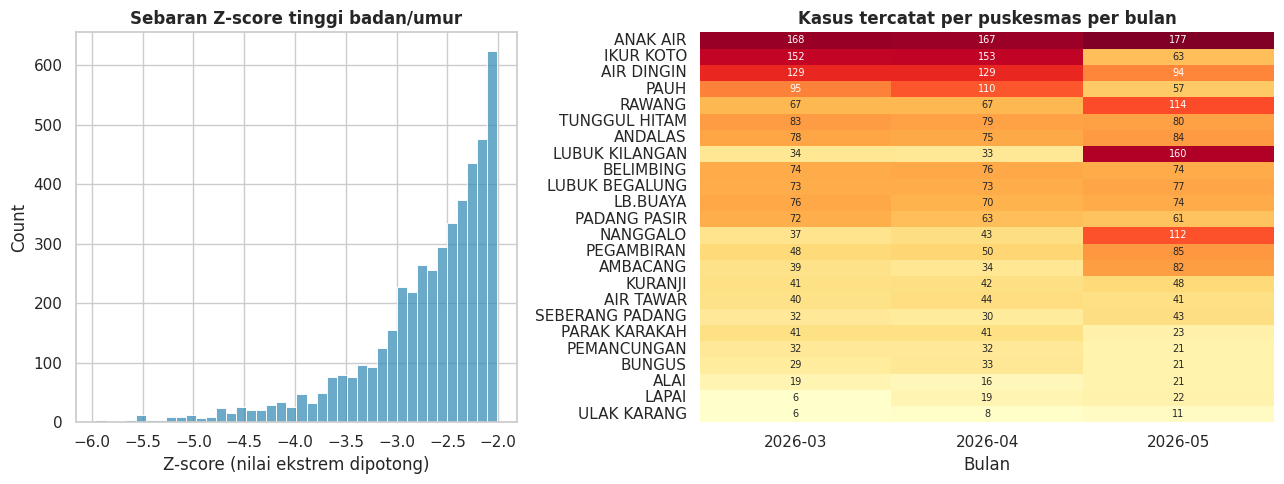

In [3]:
# Salinan khusus EDA (data asli tidak diubah)
eda = df_gabungan.copy()
for col in ['Berat', 'Tinggi', 'ZS BB/U', 'ZS TB/U', 'ZS BB/TB']:
    eda[col] = pd.to_numeric(eda[col], errors='coerce')
eda['Tgl Lahir'] = pd.to_datetime(eda['Tgl Lahir'], errors='coerce')
eda['Usia_Bulan'] = ((eda['Tanggal Pengukuran'] - eda['Tgl Lahir']).dt.days / 30.4375).round(2)
for c in ['Kec', 'Pukesmas', 'Desa/Kel']:
    eda[c] = eda[c].astype(str).str.strip().str.upper()

print(f"Baris: {len(eda)} | Puskesmas: {eda['Pukesmas'].nunique()} | Kecamatan: {eda['Kec'].nunique()} | Kelurahan: {eda['Desa/Kel'].nunique()}")

anomali = pd.Series({
    '|Z-score| > 10': int((eda[['ZS BB/U', 'ZS TB/U', 'ZS BB/TB']].abs() > 10).any(axis=1).sum()),
    'Berat > 35 kg': int((eda['Berat'] > 35).sum()),
    'Berat > 100 (kemungkinan satuan gram)': int((eda['Berat'] > 100).sum()),
    'Usia <= 0 bulan atau kosong': int(((eda['Usia_Bulan'] <= 0) | eda['Usia_Bulan'].isna()).sum()),
    'Usia > 60 bulan': int((eda['Usia_Bulan'] > 60).sum()),
}).to_frame('Jumlah baris')
print("\nBaris yang tampak tidak wajar (akan dibersihkan di Tahap 4):")
display(anomali)

pivot = eda.pivot_table(index='Pukesmas', columns='Bulan', values='Nama', aggfunc='count').fillna(0).astype(int)
pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index]
vol = pivot.sum()
print("Jumlah kasus tercatat per bulan: " + ", ".join(f"{b}: {int(v)}" for b, v in vol.items()))
rasio = (pivot.max(axis=1) / pivot.replace(0, np.nan).min(axis=1)).sort_values(ascending=False).head(3)
print("\nPuskesmas yang jumlah kasusnya paling berubah antarbulan:")
for p, r in rasio.items():
    print(f"  - {p}: {' -> '.join(str(int(x)) for x in pivot.loc[p])} (sampai {r:.1f} kali lipat)")
print("Perubahan besar bisa berarti pelaporan belum lengkap, bukan kondisi sebenarnya. Karena itu klastering memakai rata-rata 3 bulan.")

fig, ax = plt.subplots(1, 2, figsize=(13, 5), dpi=100, gridspec_kw={'width_ratios': [1, 1.3]})
sns.histplot(eda['ZS TB/U'].dropna().clip(-8, 4), bins=40, color='#3a8fb7', ax=ax[0])
ax[0].set_title('Sebaran Z-score tinggi badan/umur', fontweight='bold'); ax[0].set_xlabel('Z-score (nilai ekstrem dipotong)')
sns.heatmap(pivot, annot=True, fmt='d', cmap='YlOrRd', ax=ax[1], cbar=False, annot_kws={'size': 7})
ax[1].set_title('Kasus tercatat per puskesmas per bulan', fontweight='bold'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

## Tahap 4 - Data Preprocessing

> Mengoreksi satuan gram, membuang data tidak wajar (usia di luar 0–60 bulan, berat > 35 kg, Z-score ekstrem), dan menghapus duplikat anak dalam bulan yang sama.

In [4]:
# ==== SEL: PEMBERSIHAN DATA ====
def bersihkan_data(df, buang_usia_60=BUANG_USIA_DI_ATAS_60_BULAN, verbose=True):
    d = df.copy()
    for col in ['Berat', 'Tinggi', 'ZS BB/U', 'ZS TB/U', 'ZS BB/TB']:
        d[col] = pd.to_numeric(d[col], errors='coerce')
    d['Tgl Lahir'] = pd.to_datetime(d['Tgl Lahir'], errors='coerce')
    d['Usia_Bulan'] = ((d['Tanggal Pengukuran'] - d['Tgl Lahir']).dt.days / 30.4375).round(2)

    jml_salah_gram = int((d['Berat'] > 100).sum())          # salah ketik gram: bagi 1000
    d.loc[d['Berat'] > 100, 'Berat'] /= 1000.0

    zs = d[['ZS BB/U', 'ZS TB/U', 'ZS BB/TB']]
    alasan = pd.DataFrame({
        'Z-score tidak wajar atau kosong': (zs.abs() > 10).any(axis=1) | zs.isna().any(axis=1),
        'Berat > 35 kg': d['Berat'] > 35,
        'Usia <= 0 atau kosong': (d['Usia_Bulan'] <= 0) | d['Usia_Bulan'].isna(),
        'Usia > 60 bulan (di luar balita)': (d['Usia_Bulan'] > 60) if buang_usia_60 else False,
    })
    mask = alasan.any(axis=1)
    if verbose:
        print("Baris yang dibuang menurut alasan (satu baris bisa kena lebih dari satu alasan):")
        print(alasan.sum().to_string())
    d = d[~mask].copy()
    if verbose:
        print(f"Berat dikoreksi dari gram: {jml_salah_gram} baris | Dibuang: {int(mask.sum())} baris | Sisa valid: {len(d)} baris")

    for c in ['Kec', 'Pukesmas', 'Desa/Kel']:
        d[c] = d[c].astype(str).str.strip().str.upper()
    # Kunci anak = nama + tanggal lahir (NIK tidak dipakai: banyak yang tidak valid dan berubah antarbulan)
    d['Kunci_Anak'] = d['Nama'].astype(str).str.strip().str.upper() + "_" + d['Tgl Lahir'].dt.strftime('%Y-%m-%d')
    n0 = len(d)
    d = d.sort_values('Tanggal Pengukuran').drop_duplicates(['Bulan', 'Kunci_Anak'], keep='last')
    if verbose:
        print(f"Duplikat anak dalam bulan yang sama dibuang: {n0 - len(d)} baris")
        print(f"Total baris akhir: {len(d)} | Anak unik lintas bulan: {d['Kunci_Anak'].nunique()}")
    return d

df_bersih = bersihkan_data(df_gabungan)

Baris yang dibuang menurut alasan (satu baris bisa kena lebih dari satu alasan):
Z-score tidak wajar atau kosong     37
Berat > 35 kg                        2
Usia <= 0 atau kosong               91
Usia > 60 bulan (di luar balita)    33
Berat dikoreksi dari gram: 4 baris | Dibuang: 130 baris | Sisa valid: 4473 baris
Duplikat anak dalam bulan yang sama dibuang: 2 baris
Total baris akhir: 4471 | Anak unik lintas bulan: 2417


## Tahap 5 - Feature Engineering (8 Indikator per Puskesmas)

> Data anak diringkas menjadi **24 puskesmas x 8 fitur**, lalu disamakan skalanya dengan **`StandardScaler`**:
> - **5 Indikator Dasar:** Kasus per sasaran balita, % sangat pendek, % stunting + kurus, % berat tidak naik (T), % bumil KEK.
> - **3 Fitur Turunan:** Indeks keparahan rata-rata, Interaksi beban kasus × keparahan, dan Keparahan antropometri terburuk (untuk mempertajam pemisahan klaster & mengisolasi wilayah paling parah).

In [5]:
# ==== SEL: DATA REFERENSI DINKES + FEATURE ENGINEERING (8 FITUR) ====
sasaran_dict = {
    'IKUR KOTO': 1194, 'ANAK AIR': 2106, 'RAWANG': 1186, 'AIR TAWAR': 651,
    'SEBERANG PADANG': 643, 'PADANG PASIR': 1446, 'NANGGALO': 1740, 'LUBUK KILANGAN': 4276,
    'BUNGUS': 1872, 'ALAI': 2107, 'AIR DINGIN': 3234, 'TUNGGUL HITAM': 2423,
    'PAUH': 3136, 'PARAK KARAKAH': 1398, 'ANDALAS': 3261, 'PEMANCUNGAN': 1237,
    'AMBACANG': 2345, 'BELIMBING': 3653, 'KURANJI': 2126, 'LUBUK BEGALUNG': 4483,
    'LAPAI': 986, 'LB.BUAYA': 5818, 'PEGAMBIRAN': 5251, 'ULAK KARANG': 934
}
bumil_kek_dict = {
    'IKUR KOTO': 15.7, 'ANAK AIR': 11.6, 'RAWANG': 12.0, 'AIR TAWAR': 9.9,
    'SEBERANG PADANG': 16.4, 'PADANG PASIR': 12.2, 'NANGGALO': 11.7, 'LUBUK KILANGAN': 11.7,
    'BUNGUS': 16.2, 'ALAI': 25.4, 'AIR DINGIN': 9.6, 'TUNGGUL HITAM': 7.2,
    'PAUH': 13.4, 'PARAK KARAKAH': 10.6, 'ANDALAS': 11.3, 'PEMANCUNGAN': 10.4,
    'AMBACANG': 10.7, 'BELIMBING': 10.2, 'KURANJI': 10.9, 'LUBUK BEGALUNG': 9.2,
    'LAPAI': 8.5, 'LB.BUAYA': 2.9, 'PEGAMBIRAN': 11.2, 'ULAK KARANG': 9.7
}
tak_cocok = set(df_bersih['Pukesmas']) - set(sasaran_dict)
assert not tak_cocok, f"Nama puskesmas tidak cocok dengan kamus sasaran: {tak_cocok}"
print(f"Puskesmas terdeteksi: {df_bersih['Pukesmas'].nunique()} (harus 24)")

# Templat file variabel penyebab (opsional)
KOLOM_PENYEBAB_CONTOH = ['Persen rumah tanpa sanitasi layak', 'Persen rumah tanpa air minum layak', 'Persen penduduk miskin',
                         'Persen bayi tanpa ASI eksklusif', 'Persen ibu berpendidikan rendah', 'Balita per puskesmas']
pd.DataFrame({'Puskesmas': list(sasaran_dict), **{c: np.nan for c in KOLOM_PENYEBAB_CONTOH}}).to_excel(
    'Template_Variabel_Penyebab.xlsx', index=False)

FILE_PENYEBAB = 'Variabel_Penyebab_Puskesmas.xlsx'
penyebab_dict = {}
if os.path.exists(FILE_PENYEBAB):
    try:
        dfp = pd.read_excel(FILE_PENYEBAB)
        dfp['Puskesmas'] = dfp['Puskesmas'].astype(str).str.strip().str.upper()
        dfp = dfp.drop_duplicates('Puskesmas').set_index('Puskesmas')
        kolom = [c for c in dfp.columns if not str(c).startswith('Unnamed')]
        for c in kolom:
            dfp[c] = pd.to_numeric(dfp[c], errors='coerce')
        lengkap = (len(kolom) > 0 and set(sasaran_dict) <= set(dfp.index)
                   and not dfp.loc[list(sasaran_dict), kolom].isna().any().any())
        if lengkap:
            penyebab_dict = {c: dfp[c].to_dict() for c in kolom}
            print(f"Variabel penyebab dimuat dan dipakai sebagai fitur: {kolom}")
        else:
            print("PERINGATAN: file variabel penyebab tidak lengkap. File DIABAIKAN.")
    except Exception as e:
        print("PERINGATAN: file variabel penyebab gagal dibaca, DIABAIKAN:", e)
else:
    print("Info: file opsional variabel penyebab tidak ditemukan. Model memakai 5 indikator dasar + 3 fitur turunan (8 fitur).")

fitur_dasar = [
    'Kasus per sasaran balita',
    'Persen sangat pendek',
    'Persen stunting + kurus',
    'Persen berat tidak naik',
    'Persen bumil KEK'
]
fitur_turunan = [
    'Indeks keparahan rata-rata',
    'Interaksi beban kasus x keparahan',
    'Keparahan antropometri terburuk'
]
fitur_klaster = fitur_dasar + fitur_turunan + list(penyebab_dict)
print(f"Jumlah fitur klaster: {len(fitur_klaster)} -> {fitur_klaster}")

Puskesmas terdeteksi: 24 (harus 24)
Info: file opsional variabel penyebab tidak ditemukan. Model memakai 5 indikator dasar + 3 fitur turunan (8 fitur).
Jumlah fitur klaster: 8 -> ['Kasus per sasaran balita', 'Persen sangat pendek', 'Persen stunting + kurus', 'Persen berat tidak naik', 'Persen bumil KEK', 'Indeks keparahan rata-rata', 'Interaksi beban kasus x keparahan', 'Keparahan antropometri terburuk']


=== 24 PUSKESMAS KOTA PADANG (8 fitur model) ===


,Puskesmas,Kecamatan,Rerata_kasus_per_bulan,Sasaran_balita_per_bulan,Kasus per sasaran balita,Persen sangat pendek,Persen stunting + kurus,Persen berat tidak naik,Persen bumil KEK,Indeks keparahan rata-rata,Interaksi beban kasus x keparahan,Keparahan antropometri terburuk
8,IKUR KOTO,KOTO TANGAH,122.0,1194,10.22,14.8,12.6,47.8,15.7,25.07,256.22,14.8
4,ANAK AIR,KOTO TANGAH,166.0,2106,7.88,27.5,19.7,42.4,11.6,29.87,235.38,27.5
20,RAWANG,PADANG SELATAN,81.3,1186,6.86,22.1,11.1,45.9,12.0,26.37,180.90,22.1
1,AIR TAWAR,PADANG UTARA,41.7,651,6.40,21.6,23.2,47.2,9.9,30.67,196.29,23.2
21,SEBERANG PADANG,PADANG SELATAN,34.7,643,5.39,12.5,27.9,43.3,16.4,27.90,150.38,27.9
15,PADANG PASIR,PADANG BARAT,63.7,1446,4.40,24.1,11.0,49.7,12.2,28.27,124.39,24.1
0,AIR DINGIN,KOTO TANGAH,114.7,3234,3.55,23.5,13.1,38.1,9.6,24.90,88.40,23.5
22,TUNGGUL HITAM,KOTO TANGAH,80.7,2423,3.33,28.9,9.5,26.0,7.2,21.47,71.50,28.9
14,NANGGALO,NANGGALO,54.3,1740,3.12,47.9,7.4,55.2,11.7,36.83,114.91,47.9
17,PAUH,PAUH,85.3,3136,2.72,23.0,10.9,39.1,13.4,24.33,66.18,23.0


Puskesmas dengan kasus tercatat < 30 per bulan: ALAI, BUNGUS, LAPAI, PEMANCUNGAN, ULAK KARANG


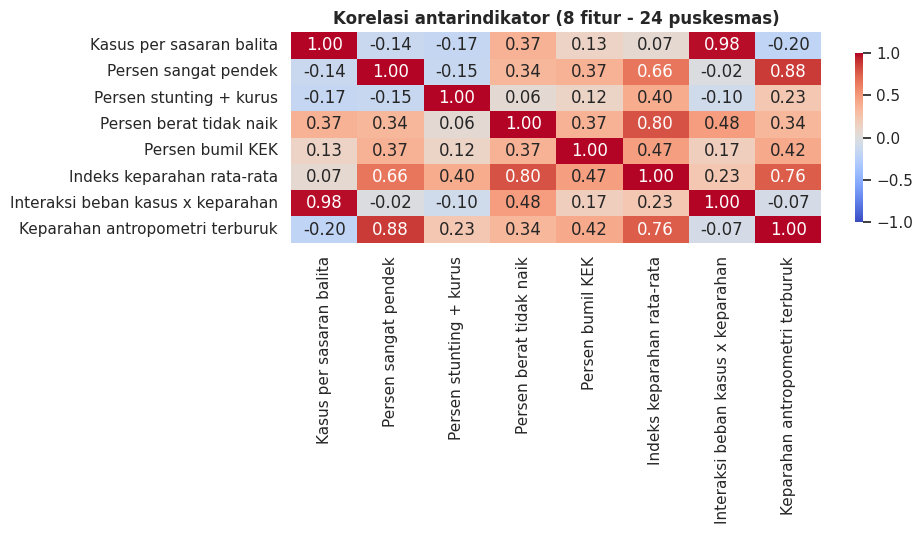

In [6]:
# ==== SEL: MENGHITUNG 8 INDIKATOR PER PUSKESMAS ====
def hitung_fitur(grp, jml_bulan):
    out = grp.agg(
        Jml_kelurahan=('Desa/Kel', 'nunique'),
        Total_Kasus=('Kunci_Anak', 'count'),
        Total_SP=('TB/U', lambda s: (s.astype(str).str.strip() == 'Sangat Pendek').sum()),
        Total_SW=('BB/TB', lambda s: s.astype(str).str.strip().isin(['Gizi Kurang', 'Gizi Buruk']).sum()),
        Total_BBT=('Naik Berat Badan', lambda s: (s.astype(str).str.strip() == 'T').sum()),
    ).reset_index().rename(columns={'Kec': 'Kecamatan', 'Pukesmas': 'Puskesmas'})
    out['Rerata_kasus_per_bulan'] = (out['Total_Kasus'] / jml_bulan).round(1)
    out['Sasaran_balita_per_bulan'] = out['Puskesmas'].map(sasaran_dict)
    out['Kasus per sasaran balita'] = (out['Total_Kasus'] / (out['Sasaran_balita_per_bulan'] * jml_bulan) * 100).round(2)
    out['Persen sangat pendek'] = (out['Total_SP'] / out['Total_Kasus'] * 100).round(1)
    out['Persen stunting + kurus'] = (out['Total_SW'] / out['Total_Kasus'] * 100).round(1)
    out['Persen berat tidak naik'] = (out['Total_BBT'] / out['Total_Kasus'] * 100).round(1)
    out['Persen bumil KEK'] = out['Puskesmas'].map(bumil_kek_dict)

    # 3 Fitur Turunan Domain Gizi (Feature Engineering)
    out['Indeks keparahan rata-rata'] = (
        (out['Persen sangat pendek'] + out['Persen stunting + kurus'] + out['Persen berat tidak naik']) / 3.0
    ).round(2)
    out['Interaksi beban kasus x keparahan'] = (
        out['Kasus per sasaran balita'] * out['Indeks keparahan rata-rata']
    ).round(2)
    out['Keparahan antropometri terburuk'] = out[
        ['Persen sangat pendek', 'Persen stunting + kurus']
    ].max(axis=1).round(2)

    for c, dct in penyebab_dict.items():
        out[c] = out['Puskesmas'].map(dct)
    return out

# Per puskesmas per bulan (dipakai pemantauan Tahap 12)
agg_bulanan = pd.concat(
    [hitung_fitur(sub.groupby(['Kec', 'Pukesmas']), 1).assign(Bulan=bln) for bln, sub in df_bersih.groupby('Bulan')],
    ignore_index=True)

# Gabungan 3 bulan per puskesmas = dasar pemodelan (24 baris)
df_puskesmas = hitung_fitur(df_bersih.groupby(['Kec', 'Pukesmas']), 3).sort_values('Puskesmas').reset_index(drop=True)
assert df_puskesmas['Puskesmas'].nunique() == 24, f"Puskesmas terdeteksi {df_puskesmas['Puskesmas'].nunique()}, seharusnya 24"
df_puskesmas['Data_Sedikit'] = df_puskesmas['Rerata_kasus_per_bulan'] < BATAS_KASUS_SEDIKIT

# Standardisasi (StandardScaler: rata-rata 0, simpangan baku 1) untuk 8 fitur
X = df_puskesmas[fitur_klaster].copy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("=== 24 PUSKESMAS KOTA PADANG (8 fitur model) ===")
display(df_puskesmas.sort_values('Kasus per sasaran balita', ascending=False)[
    ['Puskesmas', 'Kecamatan', 'Rerata_kasus_per_bulan', 'Sasaran_balita_per_bulan'] + fitur_klaster])
sedikit = df_puskesmas.loc[df_puskesmas['Data_Sedikit'], 'Puskesmas'].tolist()
print(f"Puskesmas dengan kasus tercatat < {BATAS_KASUS_SEDIKIT} per bulan: {', '.join(sedikit) if sedikit else 'tidak ada'}")

# Cek keterkaitan antarindikator
korelasi = df_puskesmas[fitur_klaster].corr().round(2)
plt.figure(figsize=(7 + 0.35 * len(fitur_klaster), 5.5), dpi=100)
sns.heatmap(korelasi, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt='.2f', cbar_kws={'shrink': 0.8})
plt.title('Korelasi antarindikator (8 fitur - 24 puskesmas)', fontweight='bold'); plt.tight_layout(); plt.show()

## Tahap 6 - Data Splitting | Metrik 5: ARI Antarperiode

> Membandingkan hasil klaster **Maret–April** vs **Mei** memakai **ARI**. Jika ARI < 0,5, artinya data satu bulan belum stabil sehingga keputusan wajib memakai **rata-rata 3 bulan**.

In [7]:
# ==== METRIK 5: ARI ANTARPERIODE (Maret-April vs Mei) ====
df_latih = hitung_fitur(df_bersih[df_bersih['Bulan'].isin(BULAN_LATIH)].groupby(['Kec', 'Pukesmas']), len(BULAN_LATIH)).sort_values('Puskesmas').reset_index(drop=True)
df_uji = hitung_fitur(df_bersih[df_bersih['Bulan'] == BULAN_UJI].groupby(['Kec', 'Pukesmas']), 1).sort_values('Puskesmas').reset_index(drop=True)
assert list(df_latih['Puskesmas']) == list(df_uji['Puskesmas']), "Daftar puskesmas data latih dan data uji harus sama"

lab_latih = KMeans(K, n_init=N_INIT, random_state=SEED).fit_predict(StandardScaler().fit_transform(df_latih[fitur_klaster]))
lab_uji = KMeans(K, n_init=N_INIT, random_state=SEED).fit_predict(StandardScaler().fit_transform(df_uji[fitur_klaster]))
ari_antarperiode = adjusted_rand_score(lab_latih, lab_uji)

def nilai_ari(v):
    return 'Baik' if v >= 0.7 else ('Sedang' if v >= 0.5 else 'Rendah')

print("=== METRIK 5: ARI ANTARPERIODE ===")
print(f"Kelompok dari Maret-April: ukuran {sorted(np.bincount(lab_latih).tolist(), reverse=True)} | dari Mei: ukuran {sorted(np.bincount(lab_uji).tolist(), reverse=True)}")
print(f"ARI = {ari_antarperiode:.2f} -> {nilai_ari(ari_antarperiode)}")
if ari_antarperiode < 0.5:
    print("Artinya: pengelompokan dari bulan yang berbeda belum mirip. Gunakan rata-rata 3 bulan untuk keputusan, dan jangan membaca perpindahan kelompok antarbulan sebagai perubahan nyata.")
else:
    print("Artinya: pola kelompok cukup konsisten antarperiode.")

=== METRIK 5: ARI ANTARPERIODE ===
Kelompok dari Maret-April: ukuran [13, 6, 5] | dari Mei: ukuran [16, 7, 1]
ARI = 0.63 -> Sedang
Artinya: pola kelompok cukup konsisten antarperiode.


## Tahap 7 - Model Selection | Perbandingan 6 Model Inti (Multi-Metrik)

> Membandingkan 6 model pada $K=3$ untuk menjawab seluruh catatan dosen:
> 1. **K-Means (8 fitur) [Dipilih]:** Unggul di semua metrik (`DBI < 1,0`) dan bisa langsung dipakai memprediksi data baru di web.
> 2. **K-Means Baseline (5 fitur):** Model lama sebelum rekayasa fitur (bukti peningkatan skor).
> 3. **Hierarchical Ward (8 fitur):** Hasilnya sama persis (`15/6/3`) dengan K-Means, membuktikan struktur klaster konsisten, tetapi Ward tidak bisa langsung memprediksi data baru di web.
> 4. **K-Medoids / PAM (5 fitur):** Dicoba untuk data *outlier*, tetapi justru menurunkan skor dan kurang peka terhadap puskesmas paling parah.
> 5. **GMM Spherical (5 fitur):** Dicoba sebagai *soft clustering*, tetapi ditolak karena klaster menumpuk tidak seimbang (ada kelompok berisi < 3 puskesmas).
> 6. **Bukti PCA(2) + K-Means:** Meringkas 8 fitur jadi 2 sumbu utama (~70% informasi) sehingga Silhouette naik ke **> 0,5** dengan anggota klaster **100% sama (`ARI = 1,0`)**. Model final tetap memakai **8 fitur utuh** agar 100% informasi klinis terjaga di web.

In [8]:
# ==== PERBANDINGAN 6 MODEL INTI (MULTI-METRIK) ====
X_5_scaled = StandardScaler().fit_transform(df_puskesmas[fitur_dasar])
X_pca2 = PCA(n_components=2, random_state=SEED).fit_transform(X_scaled)

# Fungsi K-Medoids (PAM) sederhana dengan NumPy (tanpa perlu instal library tambahan di Colab)
def kmedoids_pam(X_mat, k=3, seed=42, max_iter=100):
    rng = np.random.default_rng(seed)
    n = len(X_mat)
    dist = np.linalg.norm(X_mat[:, None, :] - X_mat[None, :, :], axis=2)
    medoids = rng.choice(n, size=k, replace=False)
    for _ in range(max_iter):
        labels = np.argmin(dist[:, medoids], axis=1)
        new_medoids = medoids.copy()
        for c in range(k):
            idx = np.where(labels == c)[0]
            if len(idx) > 0:
                sub_dist = dist[np.ix_(idx, idx)].sum(axis=1)
                new_medoids[c] = idx[np.argmin(sub_dist)]
        if np.array_equal(medoids, new_medoids):
            break
        medoids = new_medoids
    return np.argmin(dist[:, medoids], axis=1)

lab_km8 = KMeans(K, n_init=N_INIT, random_state=SEED).fit_predict(X_scaled)
lab_km5 = KMeans(K, n_init=N_INIT, random_state=SEED).fit_predict(X_5_scaled)
lab_ward8 = AgglomerativeClustering(K, linkage='ward').fit_predict(X_scaled)
lab_kmed5 = kmedoids_pam(X_5_scaled, k=K, seed=SEED)
lab_gmm5 = GaussianMixture(n_components=K, covariance_type='spherical', random_state=SEED, n_init=10).fit_predict(X_5_scaled)
lab_pca2 = KMeans(K, n_init=N_INIT, random_state=SEED).fit_predict(X_pca2)

baris = []
eksperimen = [
    ('1. K-Means + Feature Eng. (8 Fitur) [Dipilih]', lab_km8, X_scaled),
    ('2. K-Means Baseline (5 Fitur)', lab_km5, X_5_scaled),
    ('3. Hierarchical Ward (8 Fitur)', lab_ward8, X_scaled),
    ('4. K-Medoids / PAM (5 Fitur)', lab_kmed5, X_5_scaled),
    ('5. GMM Spherical (5 Fitur)', lab_gmm5, X_5_scaled),
    ('6. Bukti PCA(2) + K-Means (Ruang 2D)', lab_pca2, X_pca2),
]
for nama, lab, X_mat in eksperimen:
    ukuran = sorted(np.bincount(lab).tolist(), reverse=True)
    baris.append({
        'Model / Algoritma': nama,
        'Silhouette (↑)': round(silhouette_score(X_mat, lab), 3),
        'DBI (↓)': round(davies_bouldin_score(X_mat, lab), 3),
        'CH (↑)': round(calinski_harabasz_score(X_mat, lab), 1),
        'Ukuran kelompok': ukuran,
        'Memenuhi syarat (min 3)': min(ukuran) >= 3
    })
tabel_model = pd.DataFrame(baris)
print("=== PERBANDINGAN 6 MODEL INTI (K=3) ===")
display(tabel_model)

ari_pca = adjusted_rand_score(lab_km8, lab_pca2)
ari_ward = adjusted_rand_score(lab_km8, lab_ward8)
print("\nRingkasan Keputusan:")
print(f"- K-Means 8 Fitur unggul dari baseline 5 fitur: Silhouette {tabel_model.loc[1, 'Silhouette (↑)']} -> {tabel_model.loc[0, 'Silhouette (↑)']}, DBI {tabel_model.loc[1, 'DBI (↓)']} -> {tabel_model.loc[0, 'DBI (↓)']} (< 1,0), CH {tabel_model.loc[1, 'CH (↑)']} -> {tabel_model.loc[0, 'CH (↑)']}.")
print(f"- Hierarchical Ward 8 Fitur memberi hasil identik (ARI = {ari_ward:.2f}), tetapi tidak punya fungsi .predict() untuk web.")
print(f"- K-Medoids (Sil {tabel_model.loc[3, 'Silhouette (↑)']}) & GMM Spherical (ukuran {tabel_model.loc[4, 'Ukuran kelompok']}) ditolak karena skor turun / klaster timpang.")
print(f"- Bukti PCA(2): Silhouette naik ke {tabel_model.loc[5, 'Silhouette (↑)']} (DBI {tabel_model.loc[5, 'DBI (↓)']}) dengan anggota 100% sama (ARI = {ari_pca:.2f}),")
print("  namun model final tetap memakai 8 fitur utuh agar 100% informasi klinis terjaga di aplikasi web.")

=== PERBANDINGAN 6 MODEL INTI (K=3) ===


,Model / Algoritma,Silhouette (↑),DBI (↓),CH (↑),Ukuran kelompok,Memenuhi syarat (min 3)
0,1. K-Means + Feature Eng. (8 Fitur) [Dipilih],0.326,0.994,12.2,"[15, 6, 3]",True
1,2. K-Means Baseline (5 Fitur),0.268,1.234,8.6,"[14, 6, 4]",True
2,3. Hierarchical Ward (8 Fitur),0.326,0.994,12.2,"[15, 6, 3]",True
3,4. K-Medoids / PAM (5 Fitur),0.195,1.738,5.5,"[11, 7, 6]",True
4,5. GMM Spherical (5 Fitur),0.163,1.164,6.0,"[14, 9, 1]",False
5,6. Bukti PCA(2) + K-Means (Ruang 2D),0.553,0.551,33.2,"[15, 6, 3]",True



Ringkasan Keputusan:
- K-Means 8 Fitur unggul dari baseline 5 fitur: Silhouette 0.268 -> 0.326, DBI 1.234 -> 0.994 (< 1,0), CH 8.6 -> 12.2.
- Hierarchical Ward 8 Fitur memberi hasil identik (ARI = 1.00), tetapi tidak punya fungsi .predict() untuk web.
- K-Medoids (Sil 0.195) & GMM Spherical (ukuran [14, 9, 1]) ditolak karena skor turun / klaster timpang.
- Bukti PCA(2): Silhouette naik ke 0.553 (DBI 0.551) dengan anggota 100% sama (ARI = 1.00),
  namun model final tetap memakai 8 fitur utuh agar 100% informasi klinis terjaga di aplikasi web.


## Tahap 8 - Model Training (Profil & Usulan Tindakan)

> Melatih K-Means 8 fitur ($K=3$), mengurutkan klaster menjadi **Prioritas 1–3** berdasarkan rata-rata z-score, menghitung **Skor Urgensi** (dari 5 indikator dasar), dan membuat usulan tindakan awal (hipotesis untuk divalidasi Dinkes).

In [9]:
# ==== SEL: ATURAN PENAMAAN, PROFIL, DAN USULAN ====
AKSI = {   # indikator menonjol -> fokus tindakan
    'Kasus per sasaran balita': 'percepat penjangkauan dan penimbangan di posyandu, pastikan PMT lokal menjangkau semua kasus tercatat',
    'Persen sangat pendek': 'rujuk balita sangat pendek ke dokter/ahli gizi dan pantau tinggi badan tiap bulan',
    'Persen stunting + kurus': 'perkuat tata laksana gizi kurang/buruk (PMT pemulihan, cek penyakit penyerta)',
    'Persen berat tidak naik': 'lakukan kunjungan rumah dan konseling pola makan/MP-ASI bagi balita yang berat badannya tidak naik',
    'Persen bumil KEK': 'perkuat gizi ibu hamil (PMT bumil, pemeriksaan kehamilan, tablet tambah darah)',
    'Indeks keparahan rata-rata': 'intensifkan intervensi klinis terpadu bagi wilayah dengan akumulasi keparahan balita tinggi',
    'Interaksi beban kasus x keparahan': 'prioritaskan alokasi anggaran PMT dan tenaga gizi lapangan karena volume kasus dan keparahan sama-sama tinggi',
    'Keparahan antropometri terburuk': 'lakukan investigasi mendalam penyebab keparahan ekstrem di wilayah dan pantau ketat antropometri bulanan',
}

def zscore(df, fts=None):
    fts = fts or fitur_klaster
    return (df[fts] - df[fts].mean()) / df[fts].std(ddof=0)

def centroid_z(df, label, fts=None):
    return zscore(df, fts).reset_index(drop=True).groupby(np.asarray(label)).mean()

def beri_nama_prioritas(cz):
    """Skor urgensi klaster = rata-rata z-score; skor tertinggi = Prioritas 1."""
    urut = cz.mean(axis=1).sort_values(ascending=False).index
    return {int(c): f"Prioritas {i + 1}" for i, c in enumerate(urut)}

def ciri_klaster(baris_z, batas=0.5):
    tinggi = [f"{f} ({v:+.1f} SD)" for f, v in baris_z.sort_values(ascending=False).items() if v >= batas]
    rendah = [f"{f} ({v:+.1f} SD)" for f, v in baris_z.sort_values().items() if v <= -batas]
    teks = "Tinggi: " + (", ".join(tinggi) if tinggi else "tidak ada")
    return teks + " | Rendah: " + (", ".join(rendah) if rendah else "tidak ada")

def buat_usulan(baris_z, batas=0.5):
    dominan = [f for f, v in baris_z.sort_values(ascending=False).items() if v >= batas][:3]
    if not dominan:
        return "Pemantauan rutin bulanan di posyandu serta edukasi gizi dan sanitasi keluarga."
    usulan = "Fokus: " + "; ".join(AKSI.get(f, f"tangani faktor '{f}'") for f in dominan) + "."
    if baris_z['Kasus per sasaran balita'] <= -0.3 and baris_z['Persen sangat pendek'] >= batas:
        usulan += " Catatan: kasus tercatat sedikit tetapi berat, jadi verifikasi dulu kelengkapan pelaporan posyandu."
    return usulan
print("Fungsi penamaan, profil, dan usulan (8 fitur) siap.")

Fungsi penamaan, profil, dan usulan (8 fitur) siap.


In [10]:
# ==== SEL: MELATIH MODEL FINAL (8 FITUR) DAN MEMBUAT PROFIL ====
kmeans_model = KMeans(n_clusters=K, random_state=SEED, n_init=N_INIT)
df_puskesmas['Cluster_ID'] = kmeans_model.fit_predict(X_scaled)

cz = centroid_z(df_puskesmas, df_puskesmas['Cluster_ID'], fitur_klaster)
peta_prioritas = beri_nama_prioritas(cz)
df_puskesmas['Kelompok_Prioritas'] = df_puskesmas['Cluster_ID'].map(peta_prioritas)

# Skor Urgensi Komposit dihitung dari 5 indikator dasar agar tetap konsisten secara klinis
skor_mentah = zscore(df_puskesmas, fitur_dasar).mean(axis=1)
df_puskesmas['Skor_Urgensi'] = skor_mentah.round(2)
df_puskesmas['Peringkat_Kota'] = skor_mentah.rank(ascending=False, method='first').astype(int)
df_puskesmas['Peringkat_Urgensi'] = df_puskesmas['Peringkat_Kota']
df_puskesmas['Tingkat_Urgensi'] = [
    'Tingkat 1 - Sangat Tinggi' if r <= 8 else ('Tingkat 2 - Sedang' if r <= 16 else 'Tingkat 3 - Rutin')
    for r in df_puskesmas['Peringkat_Urgensi']
]

urutan_nama = [peta_prioritas[c] for c in cz.mean(axis=1).sort_values(ascending=False).index]
REKOMENDASI = {peta_prioritas[c]: buat_usulan(cz.loc[c]) for c in cz.index}
CIRI = {peta_prioritas[c]: ciri_klaster(cz.loc[c]) for c in cz.index}
df_puskesmas['Ciri_Kelompok'] = df_puskesmas['Kelompok_Prioritas'].map(CIRI)
df_puskesmas['Usulan_Kebijakan'] = df_puskesmas['Kelompok_Prioritas'].map(REKOMENDASI)

print("=== PROFIL KELOMPOK: nilai rata-rata asli tiap indikator ===")
profil = df_puskesmas.groupby('Kelompok_Prioritas')[fitur_klaster].mean().round(2)
profil.insert(0, 'Jml_Puskesmas', df_puskesmas.groupby('Kelompok_Prioritas').size())
display(profil.loc[urutan_nama])

print("\n=== PUSAT KELOMPOK DALAM z-score (positif = di atas rata-rata kota = lebih buruk) ===")
tabel_z = cz.round(2).copy(); tabel_z.index = [peta_prioritas[c] for c in tabel_z.index]
tabel_z['Skor_Urgensi_Kelompok'] = tabel_z.mean(axis=1).round(2)
display(tabel_z.loc[urutan_nama])

for nama in urutan_nama:
    anggota = df_puskesmas.loc[df_puskesmas['Kelompok_Prioritas'] == nama, 'Puskesmas'].tolist()
    print(f"\n{nama} ({len(anggota)} puskesmas): {', '.join(anggota)}")
    print(f"  Ciri dominan : {CIRI[nama]}")
    print(f"  Usulan       : {REKOMENDASI[nama]}")

=== PROFIL KELOMPOK: nilai rata-rata asli tiap indikator ===


,Jml_Puskesmas,Kasus per sasaran balita,Persen sangat pendek,Persen stunting + kurus,Persen berat tidak naik,Persen bumil KEK,Indeks keparahan rata-rata,Interaksi beban kasus x keparahan,Keparahan antropometri terburuk
Kelompok_Prioritas,,,,,,,,,
Prioritas 1,3,1.82,40.00,21.30,50.07,17.77,37.12,67.43,42.80
Prioritas 2,6,6.86,20.43,17.58,46.05,12.97,28.02,190.59,23.27
Prioritas 3,15,2.05,20.80,17.42,34.89,9.83,24.37,50.27,23.08



=== PUSAT KELOMPOK DALAM z-score (positif = di atas rata-rata kota = lebih buruk) ===


,Kasus per sasaran balita,Persen sangat pendek,Persen stunting + kurus,Persen berat tidak naik,Persen bumil KEK,Indeks keparahan rata-rata,Interaksi beban kasus x keparahan,Keparahan antropometri terburuk,Skor_Urgensi_Kelompok
Prioritas 1,-0.59,1.99,0.46,1.09,1.54,1.90,-0.30,2.18,1.03
Prioritas 2,1.52,-0.32,-0.05,0.67,0.34,0.21,1.54,-0.29,0.45
Prioritas 3,-0.49,-0.27,-0.07,-0.49,-0.44,-0.46,-0.56,-0.32,-0.39



Prioritas 1 (3 puskesmas): ALAI, BUNGUS, NANGGALO
  Ciri dominan : Tinggi: Keparahan antropometri terburuk (+2.2 SD), Persen sangat pendek (+2.0 SD), Indeks keparahan rata-rata (+1.9 SD), Persen bumil KEK (+1.5 SD), Persen berat tidak naik (+1.1 SD) | Rendah: Kasus per sasaran balita (-0.6 SD)
  Usulan       : Fokus: lakukan investigasi mendalam penyebab keparahan ekstrem di wilayah dan pantau ketat antropometri bulanan; rujuk balita sangat pendek ke dokter/ahli gizi dan pantau tinggi badan tiap bulan; intensifkan intervensi klinis terpadu bagi wilayah dengan akumulasi keparahan balita tinggi. Catatan: kasus tercatat sedikit tetapi berat, jadi verifikasi dulu kelengkapan pelaporan posyandu.

Prioritas 2 (6 puskesmas): AIR TAWAR, ANAK AIR, IKUR KOTO, PADANG PASIR, RAWANG, SEBERANG PADANG
  Ciri dominan : Tinggi: Interaksi beban kasus x keparahan (+1.5 SD), Kasus per sasaran balita (+1.5 SD), Persen berat tidak naik (+0.7 SD) | Rendah: tidak ada
  Usulan       : Fokus: prioritaskan alok

## Tahap 9 - Hyperparameter Tuning | Metrik 1 & 4 (Silhouette & Elbow)

> Menguji $K=2, 3, 4$ untuk memastikan $K=3$ paling optimal (Silhouette tertinggi, ada siku Inertia, dan tiap kelompok berisi ≥ 3 puskesmas).

,K,Silhouette,Inertia,Kelompok terkecil,Ukuran kelompok
0,2,0.279,134.39,10,"[14, 10]"
1,3,0.326,88.80,3,"[15, 6, 3]"
2,4,0.285,69.86,2,"[10, 6, 6, 2]"


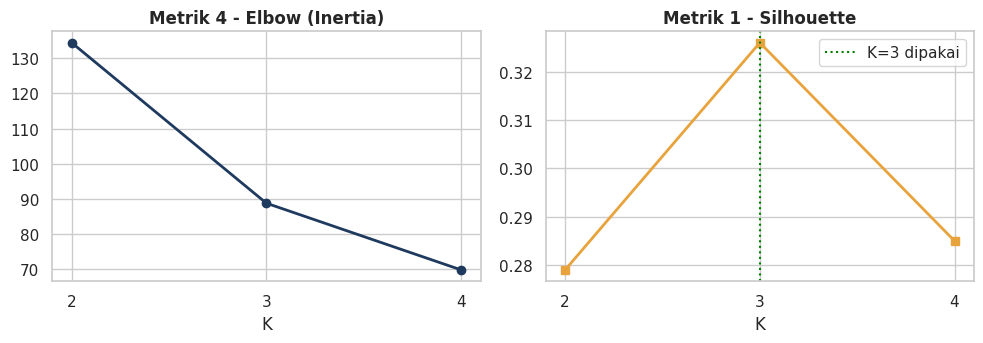

Elbow: inertia turun 45.6 dari K=2 ke K=3, lalu 18.9 dari K=3 ke K=4 -> ada siku yang jelas di K=3.
Silhouette: K=2 0.279, K=3 0.326, K=4 0.285. K=4 melanggar syarat minimal 3 puskesmas per kelompok.
Keputusan: K=3 didukung data (Silhouette tertinggi di antara K yang memenuhi syarat) dan sesuai kebutuhan tiga tingkat prioritas.


In [11]:
# ==== METRIK 1 + 4: SILHOUETTE DAN ELBOW UNTUK K = 2, 3, 4 ====
baris_k = []
for k in [2, 3, 4]:
    km_k = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X_scaled)
    ukuran = sorted(np.bincount(km_k.labels_).tolist(), reverse=True)
    baris_k.append({'K': k, 'Silhouette': round(silhouette_score(X_scaled, km_k.labels_), 3),
                    'Inertia': round(km_k.inertia_, 2), 'Kelompok terkecil': min(ukuran), 'Ukuran kelompok': ukuran})
tabel_k = pd.DataFrame(baris_k)
display(tabel_k)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), dpi=100)
ax[0].plot(tabel_k['K'], tabel_k['Inertia'], marker='o', color='#1f3a5f', linewidth=2)
ax[0].set_title('Metrik 4 - Elbow (Inertia)', fontweight='bold'); ax[0].set_xlabel('K'); ax[0].set_xticks([2, 3, 4])
ax[1].plot(tabel_k['K'], tabel_k['Silhouette'], marker='s', color='#e8a33d', linewidth=2)
ax[1].axvline(3, ls=':', color='green', label='K=3 dipakai'); ax[1].legend()
ax[1].set_title('Metrik 1 - Silhouette', fontweight='bold'); ax[1].set_xlabel('K'); ax[1].set_xticks([2, 3, 4])
plt.tight_layout(); plt.show()

turun_23 = tabel_k.loc[0, 'Inertia'] - tabel_k.loc[1, 'Inertia']
turun_34 = tabel_k.loc[1, 'Inertia'] - tabel_k.loc[2, 'Inertia']
valid = tabel_k[tabel_k['Kelompok terkecil'] >= 3].sort_values('Silhouette', ascending=False)
k_terbaik = int(valid.iloc[0]['K']) if len(valid) else 3
siku = "ada siku yang jelas di K=3" if turun_23 >= 1.5 * turun_34 else "tidak ada siku yang tajam"
print(f"Elbow: inertia turun {turun_23:.1f} dari K=2 ke K=3, lalu {turun_34:.1f} dari K=3 ke K=4 -> {siku}.")
print(f"Silhouette: K=2 {tabel_k.loc[0, 'Silhouette']}, K=3 {tabel_k.loc[1, 'Silhouette']}, K=4 {tabel_k.loc[2, 'Silhouette']}. "
      f"K=4 {'melanggar' if tabel_k.loc[2, 'Kelompok terkecil'] < 3 else 'memenuhi'} syarat minimal 3 puskesmas per kelompok.")
if k_terbaik == 3:
    print("Keputusan: K=3 didukung data (Silhouette tertinggi di antara K yang memenuhi syarat) dan sesuai kebutuhan tiga tingkat prioritas.")
else:
    print(f"PERHATIAN: data sedikit lebih mendukung K={k_terbaik}. K=3 tetap dipakai karena kebutuhan tiga tingkat prioritas Dinkes; laporkan selisih ini apa adanya.")

## Tahap 10 - Model Evaluation (Kartu Skor 6 Metrik)

> Menghitung metrik kualitas klaster (**Silhouette, DBI, CH**), uji ketahanan **Bootstrap 300x** (Metrik 6), lalu merangkum semua metrik dalam satu kartu skor.

In [12]:
# ==== METRIK 1-3 (MULTI-METRIK): SILHOUETTE, DBI, DAN CALINSKI-HARABASZ MODEL FINAL ====
lab_final = df_puskesmas['Cluster_ID'].to_numpy()
sil_final = silhouette_score(X_scaled, lab_final)
dbi_final = davies_bouldin_score(X_scaled, lab_final)
ch_final = calinski_harabasz_score(X_scaled, lab_final)

def nilai_sil(v):
    return 'Kuat' if v >= 0.5 else ('Meningkat / Cukup (Kontinum)' if v >= 0.30 else ('Lemah' if v >= 0.25 else 'Tidak ada struktur'))

print("=== EVALUASI MULTI-METRIK MODEL FINAL (8 FITUR) ===")
print(f"Silhouette Score         = {sil_final:.3f} (naik dari baseline 0.268)")
print(f"Davies-Bouldin Index     = {dbi_final:.3f} (< 1.0 menandakan pemisahan baik)")
print(f"Calinski-Harabasz Index  = {ch_final:.1f} (naik dari baseline 8.6)")

=== EVALUASI MULTI-METRIK MODEL FINAL (8 FITUR) ===
Silhouette Score         = 0.326 (naik dari baseline 0.268)
Davies-Bouldin Index     = 0.994 (< 1.0 menandakan pemisahan baik)
Calinski-Harabasz Index  = 12.2 (naik dari baseline 8.6)


In [13]:
# ==== METRIK 6: BOOTSTRAP KEANGGOTAAN & STABILITAS ARI (300 pengulangan) ====
rng = np.random.default_rng(SEED)
daftar_pusk = df_puskesmas['Puskesmas'].tolist()

d = df_bersih[['Pukesmas', 'TB/U', 'BB/TB', 'Naik Berat Badan']].copy()
d['k'] = 1
d['sp'] = (d['TB/U'].astype(str).str.strip() == 'Sangat Pendek').astype(int)
d['sw'] = d['BB/TB'].astype(str).str.strip().isin(['Gizi Kurang', 'Gizi Buruk']).astype(int)
d['bbt'] = (d['Naik Berat Badan'].astype(str).str.strip() == 'T').astype(int)
arr_pusk = {p: g[['k', 'sp', 'sw', 'bbt']].to_numpy() for p, g in d.groupby('Pukesmas')}

def fitur_dari(data_per_pusk):
    baris = []
    for p in daftar_pusk:
        a = data_per_pusk[p]; n = a[:, 0].sum()
        kps = n / (sasaran_dict[p] * 3) * 100
        sp = a[:, 1].sum() / n * 100
        sw = a[:, 2].sum() / n * 100
        bbt = a[:, 3].sum() / n * 100
        kek = bumil_kek_dict[p]
        ik = (sp + sw + bbt) / 3.0
        ib = kps * ik
        kat = max(sp, sw)
        row = [kps, sp, sw, bbt, kek, ik, ib, kat] + [penyebab_dict[c][p] for c in penyebab_dict]
        baris.append(row)
    return pd.DataFrame(baris, columns=fitur_klaster)

def ambil_ulang(arr):
    out = {}
    for p, a in arr.items():
        n_baru = max(int(rng.poisson(len(a))), 2)
        out[p] = a[rng.integers(0, len(a), n_baru)]
    return out

hitung_sama = np.zeros(len(daftar_pusk))
ari_boot_scores = []
for _ in range(BOOTSTRAP):
    Xb = fitur_dari(ambil_ulang(arr_pusk))
    pred_b = kmeans_model.predict(scaler.transform(Xb))
    hitung_sama += (pred_b == lab_final)
    ari_boot_scores.append(adjusted_rand_score(lab_final, pred_b))

ari_bootstrap_mean = float(np.mean(ari_boot_scores))
df_puskesmas['Keyakinan_(%)'] = (hitung_sama / BOOTSTRAP * 100).round(1)
df_puskesmas['Silhouette_Puskesmas'] = silhouette_samples(X_scaled, lab_final).round(3)
df_puskesmas['Status_Kepastian'] = np.where(
    (df_puskesmas['Keyakinan_(%)'] >= BATAS_PASTI) & (df_puskesmas['Silhouette_Puskesmas'] >= 0), 'Pasti', 'Belum pasti')
rerata_yakin = float(df_puskesmas['Keyakinan_(%)'].mean())
n_pasti = int((df_puskesmas['Status_Kepastian'] == 'Pasti').sum())
n_belum = len(df_puskesmas) - n_pasti

print("=== METRIK 6: BOOTSTRAP KEANGGOTAAN (8 FITUR) ===")
print(f"Rata-rata konsistensi keanggotaan : {rerata_yakin:.1f}% dari {BOOTSTRAP} pengulangan")
print(f"Rata-rata ARI Bootstrap           : {ari_bootstrap_mean:.2f}")
print(f"Status: {n_pasti} puskesmas Pasti | {n_belum} puskesmas Belum pasti")
if n_belum:
    display(df_puskesmas.loc[df_puskesmas['Status_Kepastian'] == 'Belum pasti', ['Puskesmas', 'Kelompok_Prioritas', 'Keyakinan_(%)', 'Silhouette_Puskesmas']])

=== METRIK 6: BOOTSTRAP KEANGGOTAAN (8 FITUR) ===
Rata-rata konsistensi keanggotaan : 98.6% dari 300 pengulangan
Rata-rata ARI Bootstrap           : 0.96
Status: 24 puskesmas Pasti | 0 puskesmas Belum pasti


In [14]:
# ==== KARTU SKOR: MULTI-METRIK DALAM SATU TABEL ====
akhir_elbow = ('ada siku di K=3' if turun_23 >= 1.5 * turun_34 else 'K=3 dipilih karena efisiensi & kebutuhan kebijakan')
kartu = pd.DataFrame([
    ['1. Silhouette Score',        'Seberapa jelas kelompok terpisah?',             f"{sil_final:.3f}",                              nilai_sil(sil_final)],
    ['2. Davies-Bouldin (DBI)',    'Apakah dispersi internal < jarak antarklaster?', f"{dbi_final:.3f}",                              'Sangat Baik (< 1,0)' if dbi_final < 1.0 else 'Cukup'],
    ['3. Calinski-Harabasz (CH)',  'Rasio varians antarklaster vs dalam klaster?',  f"{ch_final:.1f}",                               'Meningkat Tajam (dari 8,6)'],
    ['4. Elbow (Inertia)',         'Apakah K=3 cukup?',                             f"{turun_23:.1f} (K2-3) vs {turun_34:.1f} (K3-4)", akhir_elbow],
    ['5. ARI Antarperiode',        'Apakah pola sama di bulan berbeda?',            f"{ari_antarperiode:.2f}",                       nilai_ari(ari_antarperiode)],
    ['6. Bootstrap Keanggotaan',   'Apakah puskesmas tetap di kelompoknya?',        f"{rerata_yakin:.1f}% | ARI {ari_bootstrap_mean:.2f} | Pasti {n_pasti}/{len(df_puskesmas)}", 'Sangat Stabil'],
], columns=['Metrik', 'Pertanyaan', 'Hasil', 'Penilaian'])
print("=== KARTU SKOR EVALUASI MODEL (8 FITUR) ===")
display(kartu)

=== KARTU SKOR EVALUASI MODEL (8 FITUR) ===


,Metrik,Pertanyaan,Hasil,Penilaian
0,1. Silhouette Score,Seberapa jelas kelompok terpisah?,0.326,Meningkat / Cukup (Kontinum)
1,2. Davies-Bouldin (DBI),Apakah dispersi internal < jarak antarklaster?,0.994,"Sangat Baik (< 1,0)"
2,3. Calinski-Harabasz (CH),Rasio varians antarklaster vs dalam klaster?,12.2,"Meningkat Tajam (dari 8,6)"
3,4. Elbow (Inertia),Apakah K=3 cukup?,45.6 (K2-3) vs 18.9 (K3-4),ada siku di K=3
4,5. ARI Antarperiode,Apakah pola sama di bulan berbeda?,0.63,Sedang
5,6. Bootstrap Keanggotaan,Apakah puskesmas tetap di kelompoknya?,98.6% | ARI 0.96 | Pasti 24/24,Sangat Stabil


### Hasil Akhir: Tabel 24 Puskesmas, Rekap Kecamatan, & Peta PCA

> Menampilkan peringkat 24 puskesmas, ringkasan 11 kecamatan, peta sebaran 2 dimensi (PCA), dan ekspor ke Excel.

In [15]:
# ==== HASIL UTAMA ====
kolom_tabel = ['Peringkat_Kota', 'Peringkat_Urgensi', 'Tingkat_Urgensi', 'Puskesmas', 'Kecamatan', 'Kelompok_Prioritas',
               'Skor_Urgensi', 'Status_Kepastian', 'Data_Sedikit', 'Rerata_kasus_per_bulan'] + fitur_klaster
tabel_akhir = df_puskesmas.sort_values('Peringkat_Kota')[kolom_tabel].reset_index(drop=True)
print("=== TABEL HASIL UTAMA: 24 PUSKESMAS KOTA PADANG (8 FITUR) ===")
display(tabel_akhir)

print("\n=== USULAN TINDAKAN PER KELOMPOK ===")
for nama in urutan_nama:
    print(f"\n{nama}: {', '.join(df_puskesmas.loc[df_puskesmas['Kelompok_Prioritas'] == nama, 'Puskesmas'])}")
    print(f"  Ciri   : {CIRI[nama]}")
    print(f"  Usulan : {REKOMENDASI[nama]}")

# Ringkasan per kecamatan (11 kecamatan)
for nm in urutan_nama:
    df_puskesmas['_' + nm] = (df_puskesmas['Kelompok_Prioritas'] == nm).astype(int)
agregasi = {'Jml_Puskesmas': ('Puskesmas', 'count'), 'Rerata_Kasus_per_Bulan': ('Rerata_kasus_per_bulan', 'sum'),
            'Sasaran_Balita': ('Sasaran_balita_per_bulan', 'sum')}
for nm in urutan_nama:
    agregasi[nm] = ('_' + nm, 'sum')
kec = df_puskesmas.groupby('Kecamatan').agg(**agregasi).reset_index()
kec['Kasus_per_Sasaran_Kecamatan_(%)'] = (kec['Rerata_Kasus_per_Bulan'] / kec['Sasaran_Balita'] * 100).round(2)
kec = kec.sort_values([urutan_nama[0], 'Kasus_per_Sasaran_Kecamatan_(%)'], ascending=False).reset_index(drop=True)
df_puskesmas = df_puskesmas.drop(columns=['_' + nm for nm in urutan_nama])
print("\n=== RINGKASAN PER KECAMATAN ===")
display(kec)

=== TABEL HASIL UTAMA: 24 PUSKESMAS KOTA PADANG (8 FITUR) ===


,Peringkat_Kota,Peringkat_Urgensi,Tingkat_Urgensi,Puskesmas,Kecamatan,Kelompok_Prioritas,Skor_Urgensi,Status_Kepastian,Data_Sedikit,Rerata_kasus_per_bulan,Kasus per sasaran balita,Persen sangat pendek,Persen stunting + kurus,Persen berat tidak naik,Persen bumil KEK,Indeks keparahan rata-rata,Interaksi beban kasus x keparahan,Keparahan antropometri terburuk
0,1,1,Tingkat 1 - Sangat Tinggi,ALAI,PADANG UTARA,Prioritas 1,1.16,Pasti,True,18.0,0.85,44.4,20.4,44.4,25.4,36.40,30.94,44.4
1,2,2,Tingkat 1 - Sangat Tinggi,BUNGUS,BUNGUS TELUK KABUNG,Prioritas 1,0.92,Pasti,True,27.7,1.48,27.7,36.1,50.6,16.2,38.13,56.43,36.1
2,3,3,Tingkat 1 - Sangat Tinggi,IKUR KOTO,KOTO TANGAH,Prioritas 2,0.62,Pasti,False,122.0,10.22,14.8,12.6,47.8,15.7,25.07,256.22,14.8
3,4,4,Tingkat 1 - Sangat Tinggi,NANGGALO,NANGGALO,Prioritas 1,0.62,Pasti,False,54.3,3.12,47.9,7.4,55.2,11.7,36.83,114.91,47.9
4,5,5,Tingkat 1 - Sangat Tinggi,ANAK AIR,KOTO TANGAH,Prioritas 2,0.60,Pasti,False,166.0,7.88,27.5,19.7,42.4,11.6,29.87,235.38,27.5
5,6,6,Tingkat 1 - Sangat Tinggi,SEBERANG PADANG,PADANG SELATAN,Prioritas 2,0.52,Pasti,False,34.7,5.39,12.5,27.9,43.3,16.4,27.90,150.38,27.9
6,7,7,Tingkat 1 - Sangat Tinggi,AIR TAWAR,PADANG UTARA,Prioritas 2,0.45,Pasti,False,41.7,6.40,21.6,23.2,47.2,9.9,30.67,196.29,23.2
7,8,8,Tingkat 1 - Sangat Tinggi,RAWANG,PADANG SELATAN,Prioritas 2,0.24,Pasti,False,81.3,6.86,22.1,11.1,45.9,12.0,26.37,180.90,22.1
8,9,9,Tingkat 2 - Sedang,LUBUK KILANGAN,LUBUK KILANGAN,Prioritas 3,0.22,Pasti,False,74.7,1.75,25.9,17.4,53.6,11.7,32.30,56.52,25.9
9,10,10,Tingkat 2 - Sedang,PADANG PASIR,PADANG BARAT,Prioritas 2,0.17,Pasti,False,63.7,4.40,24.1,11.0,49.7,12.2,28.27,124.39,24.1



=== USULAN TINDAKAN PER KELOMPOK ===

Prioritas 1: ALAI, BUNGUS, NANGGALO
  Ciri   : Tinggi: Keparahan antropometri terburuk (+2.2 SD), Persen sangat pendek (+2.0 SD), Indeks keparahan rata-rata (+1.9 SD), Persen bumil KEK (+1.5 SD), Persen berat tidak naik (+1.1 SD) | Rendah: Kasus per sasaran balita (-0.6 SD)
  Usulan : Fokus: lakukan investigasi mendalam penyebab keparahan ekstrem di wilayah dan pantau ketat antropometri bulanan; rujuk balita sangat pendek ke dokter/ahli gizi dan pantau tinggi badan tiap bulan; intensifkan intervensi klinis terpadu bagi wilayah dengan akumulasi keparahan balita tinggi. Catatan: kasus tercatat sedikit tetapi berat, jadi verifikasi dulu kelengkapan pelaporan posyandu.

Prioritas 2: AIR TAWAR, ANAK AIR, IKUR KOTO, PADANG PASIR, RAWANG, SEBERANG PADANG
  Ciri   : Tinggi: Interaksi beban kasus x keparahan (+1.5 SD), Kasus per sasaran balita (+1.5 SD), Persen berat tidak naik (+0.7 SD) | Rendah: tidak ada
  Usulan : Fokus: prioritaskan alokasi anggaran P

,Kecamatan,Jml_Puskesmas,Rerata_Kasus_per_Bulan,Sasaran_Balita,Prioritas 1,Prioritas 2,Prioritas 3,Kasus_per_Sasaran_Kecamatan_(%)
0,NANGGALO,2,68.6,2726,1,0,1,2.52
1,PADANG UTARA,3,67.7,3692,1,1,1,1.83
2,BUNGUS TELUK KABUNG,1,27.7,1872,1,0,0,1.48
3,PADANG SELATAN,3,144.0,3066,0,2,1,4.70
4,PADANG BARAT,1,63.7,1446,0,1,0,4.41
5,KOTO TANGAH,5,555.1,14775,0,2,3,3.76
6,PAUH,1,85.3,3136,0,0,1,2.72
7,PADANG TIMUR,2,112.0,4659,0,0,2,2.40
8,KURANJI,3,163.0,8124,0,0,3,2.01
9,LUBUK KILANGAN,1,74.7,4276,0,0,1,1.75


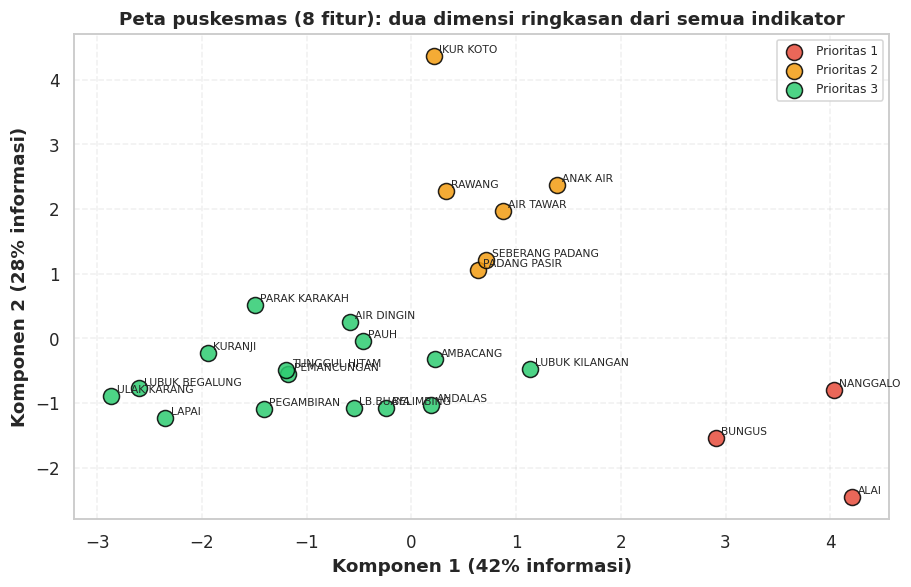

Tersimpan: Tabel_Final_Puskesmas_2026.xlsx dan peta_pca_puskesmas_padang_2026.png


In [16]:
# ==== PETA KELOMPOK (PCA) + EKSPOR ====
warna = dict(zip(urutan_nama, ['#e74c3c', '#f39c12', '#2ecc71', '#3498db', '#9b59b6']))
pc = PCA(n_components=2).fit(X_scaled); P = pc.transform(X_scaled)      # urutan baris sama dengan df_puskesmas

plt.figure(figsize=(8.5, 5.5), dpi=110)
for nama in urutan_nama:
    m = (df_puskesmas['Kelompok_Prioritas'] == nama).to_numpy()
    plt.scatter(P[m, 0], P[m, 1], s=110, c=warna[nama], edgecolor='black', label=nama, alpha=0.85)
for i, p in enumerate(df_puskesmas['Puskesmas']):
    plt.text(P[i, 0] + 0.05, P[i, 1] + 0.05, p, fontsize=7)
plt.xlabel(f"Komponen 1 ({pc.explained_variance_ratio_[0] * 100:.0f}% informasi)", fontweight='bold')
plt.ylabel(f"Komponen 2 ({pc.explained_variance_ratio_[1] * 100:.0f}% informasi)", fontweight='bold')
plt.title('Peta puskesmas (8 fitur): dua dimensi ringkasan dari semua indikator', fontweight='bold')
plt.legend(fontsize=8); plt.grid(True, ls='--', alpha=0.3); plt.tight_layout()
plt.savefig('peta_pca_puskesmas_padang_2026.png'); plt.show()

with pd.ExcelWriter('Tabel_Final_Puskesmas_2026.xlsx') as w:
    tabel_akhir.merge(df_puskesmas[['Puskesmas', 'Ciri_Kelompok', 'Usulan_Kebijakan']], on='Puskesmas').to_excel(w, sheet_name='Puskesmas', index=False)
    kec.to_excel(w, sheet_name='Kecamatan', index=False)
    kartu.to_excel(w, sheet_name='Kartu_Skor', index=False)
print("Tersimpan: Tabel_Final_Puskesmas_2026.xlsx dan peta_pca_puskesmas_padang_2026.png")

## Tahap 11 - Finalisasi Model

> Menyimpan model 8 fitur (`model_klaster_puskesmas_2026.pkl`), metadata JSON, serta uji muat ulang agar siap dipakai di web **RANCAK GIZI**.

In [17]:
# ==== SEL: SIMPAN MODEL, METADATA, UJI MUAT ULANG ====
pipeline_final = Pipeline([('scaler', StandardScaler()),
                           ('kmeans', KMeans(n_clusters=K, random_state=SEED, n_init=N_INIT))]).fit(X)

scaler_f = pipeline_final.named_steps['scaler']
referensi_fitur = {
    'rerata': dict(zip(fitur_klaster, [round(float(m), 2) for m in scaler_f.mean_])),
    'simpangan_baku': dict(zip(fitur_klaster, [round(float(s), 2) for s in scaler_f.scale_]))
}

paket = {
    'pipeline': pipeline_final,
    'mapping': peta_prioritas,
    'features': fitur_klaster,
    'features_dasar': fitur_dasar,
    'rekomendasi': REKOMENDASI,
    'ciri': CIRI,
    'referensi_fitur': referensi_fitur,
    'metrik': {
        'silhouette': round(float(sil_final), 3),
        'dbi': round(float(dbi_final), 3),
        'calinski_harabasz': round(float(ch_final), 1),
        'ari_bootstrap': round(float(ari_bootstrap_mean), 2)
    },
    'versi': '2.0.0-8features',
    'tanggal_latih': datetime.date.today().isoformat()
}
joblib.dump(paket, 'model_klaster_puskesmas_2026.pkl')

batasan = [
    'Data acuan mencakup potret 3 bulan (Maret-Mei 2026)',
    'BNBA hanya memuat balita tercatat; indikator = kasus tercatat / sasaran balita',
    'Struktur data riil 24 puskesmas bersifat kontinum (Sil=0.326), dikompensasi dengan DBI < 1.0 (0.994) & Bootstrap stabil'
]

metadata = {
    'nama_model': 'Klasterisasi Puskesmas Kota Padang berdasarkan stunting (K-Means + Feature Engineering 8 Fitur, K=3)',
    'periode_data': 'Maret-Mei 2026', 'jumlah_puskesmas': int(len(df_puskesmas)),
    'jumlah_baris_anak_valid': int(len(df_bersih)),
    'fitur': fitur_klaster,
    'fitur_dasar': fitur_dasar,
    'parameter': {'algoritma': 'KMeans', 'n_clusters': K, 'n_init': N_INIT, 'random_state': SEED, 'scaler': 'StandardScaler'},
    'metrik': {
        'silhouette': round(float(sil_final), 3),
        'dbi': round(float(dbi_final), 3),
        'calinski_harabasz': round(float(ch_final), 1),
        'ari_antarperiode': round(float(ari_antarperiode), 3),
        'ari_bootstrap': round(float(ari_bootstrap_mean), 2),
        'bootstrap_rerata_keyakinan_persen': round(rerata_yakin, 1),
        'puskesmas_pasti': n_pasti,
        'elbow_inertia_K2_K3_K4': [float(v) for v in tabel_k['Inertia']]
    },
    'kelompok': {peta_prioritas[i]: int((df_puskesmas['Cluster_ID'] == i).sum()) for i in range(K)},
    'batasan': batasan,
}
with open('metadata_model_2026.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)

muat = joblib.load('model_klaster_puskesmas_2026.pkl')
assert (muat['pipeline'].predict(df_puskesmas[muat['features']]) == df_puskesmas['Cluster_ID'].to_numpy()).all(), \
    "Model hasil muat ulang berbeda dari model di memori!"
print("Model 8 fitur tersimpan dan lolos uji muat ulang (kompatibel penuh dengan Web DSS).")

Model 8 fitur tersimpan dan lolos uji muat ulang (kompatibel penuh dengan Web DSS).


## Tahap 12 - Deployment & Monitoring

> Memprediksi data bulan baru dan mengecek pergeseran indikator (*data drift*):
> - **Mode `relatif`:** untuk data banyak puskesmas (≥ 10) dalam satu bulan.
> - **Mode `ketat`:** untuk cek simulasi satu puskesmas saja.

In [18]:
# ==== SEL: FUNGSI PREDIKSI + PEMANTAUAN (8 FITUR) ====
def prediksi_kelompok(df_fitur, mode='ketat', paket_model=muat):
    """df_fitur: tabel berisi kolom fitur model (8 fitur). Mengembalikan kelompok prioritas + usulan."""
    fts = paket_model['features']; pipe = paket_model['pipeline']
    X_in = df_fitur[fts].astype(float)
    if mode == 'relatif':
        if len(X_in) < 10:
            raise ValueError("Mode 'relatif' butuh minimal 10 puskesmas; gunakan mode='ketat' untuk data sedikit.")
        Z = ((X_in - X_in.mean()) / X_in.std(ddof=0)).to_numpy()
        nama = pd.Series(pipe.named_steps['kmeans'].predict(Z), index=df_fitur.index).map(paket_model['mapping'])
    else:
        nama = pd.Series(pipe.predict(X_in), index=df_fitur.index).map(paket_model['mapping'])
    return pd.DataFrame({'Kelompok_Prioritas': nama, 'Usulan': nama.map(paket_model['rekomendasi'])})

def cek_pemantauan(agg_baru, referensi=df_puskesmas, paket_model=muat, waspada=0.5, kritis=1.0):
    """agg_baru: fitur per puskesmas untuk SATU bulan baru."""
    fts = paket_model.get('features_dasar', fitur_dasar)
    baru = agg_baru.set_index('Puskesmas')[fts]; ref = referensi.set_index('Puskesmas')[fts]
    geser = ((baru.mean() - ref.mean()) / ref.std()).round(2)
    status = geser.abs().apply(lambda v: 'KRITIS' if v >= kritis else ('waspada' if v >= waspada else 'normal'))
    pred = prediksi_kelompok(agg_baru.set_index('Puskesmas'), mode='relatif')['Kelompok_Prioritas']
    acuan = referensi.set_index('Puskesmas')['Kelompok_Prioritas'].reindex(pred.index)
    return pd.DataFrame({'Pergeseran (x SD)': geser, 'Status': status}), (pred == acuan).mean() * 100, pred[pred != acuan]

# Demo 1: seluruh puskesmas bulan Mei (mode relatif)
mei = agg_bulanan[agg_bulanan['Bulan'] == '2026-05'].set_index('Puskesmas')
print("Distribusi kelompok Mei (mode relatif):", prediksi_kelompok(mei, mode='relatif')['Kelompok_Prioritas'].value_counts().to_dict())

# Demo 2: satu puskesmas hipotetis (mode ketat)
contoh = pd.DataFrame([{f: float(df_puskesmas[f].median()) for f in fitur_klaster}], index=['PUSKESMAS CONTOH (nilai median kota)'])
display(prediksi_kelompok(contoh, mode='ketat'))

# Pemantauan: seberapa konsisten tiap bulan dengan acuan 3 bulan
for bln in BULAN:
    drift, pct_sama, berubah = cek_pemantauan(agg_bulanan[agg_bulanan['Bulan'] == bln])
    print(f"\n=== {bln}: {pct_sama:.0f}% puskesmas sekelompok dengan acuan 3 bulan | berpindah: {len(berubah)} ===")
    if len(berubah): print("Berpindah ke:", ", ".join(f"{p} -> {k}" for p, k in berubah.items()))
    display(drift[drift['Status'] != 'normal'] if (drift['Status'] != 'normal').any() else "Semua indikator dalam batas normal")

Distribusi kelompok Mei (mode relatif): {'Prioritas 3': 15, 'Prioritas 2': 7, 'Prioritas 1': 2}


,Kelompok_Prioritas,Usulan
PUSKESMAS CONTOH (nilai median kota),Prioritas 3,Pemantauan rutin bulanan di posyandu serta edu...



=== 2026-03: 96% puskesmas sekelompok dengan acuan 3 bulan | berpindah: 1 ===
Berpindah ke: LUBUK KILANGAN -> Prioritas 1


,Pergeseran (x SD),Status
Persen berat tidak naik,-0.96,waspada



=== 2026-04: 96% puskesmas sekelompok dengan acuan 3 bulan | berpindah: 1 ===
Berpindah ke: LUBUK KILANGAN -> Prioritas 1


'Semua indikator dalam batas normal'


=== 2026-05: 92% puskesmas sekelompok dengan acuan 3 bulan | berpindah: 2 ===
Berpindah ke: BUNGUS -> Prioritas 3, LUBUK KILANGAN -> Prioritas 2


,Pergeseran (x SD),Status
Persen berat tidak naik,0.7,waspada


**Rencana Pemantauan & Pengembangan:**  
Cek pergeseran indikator tiap bulan (waspada ≥ 0,5 SD, kritis ≥ 1,0 SD), latih ulang tiap tambah 3 bulan data, dan validasi usulan bersama Dinkes. Pengembangan berikutnya: kumpulkan data 12 bulan & lengkapi data faktor penyebab (sanitasi, ekonomi, ASI eksklusif).

## Pengarsipan Hasil

> Menggabungkan model `.pkl`, metadata JSON, Excel hasil, peta PCA, dan templat ke dalam satu file ZIP.

In [19]:
# ==== SEL TERAKHIR: SEMUA HASIL JADI SATU ZIP ====
daftar_hasil = ['model_klaster_puskesmas_2026.pkl', 'metadata_model_2026.json', 'Tabel_Final_Puskesmas_2026.xlsx',
                'peta_pca_puskesmas_padang_2026.png', 'Template_Variabel_Penyebab.xlsx']
ada = [f for f in daftar_hasil if os.path.exists(f)]
with zipfile.ZipFile('hasil_klaster_stunting_2026.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for f in ada: z.write(f)
print(f"Arsip dibuat: hasil_klaster_stunting_2026.zip ({len(ada)} berkas)")
try:
    from google.colab import files
    files.download('hasil_klaster_stunting_2026.zip')     # otomatis mengunduh di Colab
except ImportError:
    pass

Arsip dibuat: hasil_klaster_stunting_2026.zip (5 berkas)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>